# Check cleaned temperatures

Compare the **observed** and **inserted** daily temperatures from `data/cleaned`.
This notebook reads the existing files through `load_cleaned_data()`, including its freshness checks; it does not rerun cleanup or change the data.

- **Solid blue / green:** observed Nikkaluokta / Tarfala temperatures.
- **Dashed orange / purple with points:** inserted Nikkaluokta / Tarfala estimates.
- **Pale shaded band in a zoom:** the selected original gap.
- **Grey curve in a zoom:** the other station's observed temperature for reference.

The dashed segments connect to adjacent observations where available. **Only the coloured points are estimated days.**
Candidate temperatures remain experimental; visually smooth joins do not establish accuracy.

Select the project's Python kernel, then **Run All**. If the data are missing or stale, run `python -m kalix.prepare` and `python -m kalix.cleanup` first.

In [1]:
%matplotlib inline
import math
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from kalix.cleanup import TEMPERATURES, load_cleaned_data
from kalix.data import project_root

ROOT = project_root(Path.cwd())
cleaned = load_cleaned_data(ROOT)

STATIONS = {
    "nikkaluokta_temperature": {
        "label": "Nikkaluokta",
        "observed": "#0072B2",
        "inserted": "#D55E00",
        "marker": "o",
    },
    "tarfala_temperature": {
        "label": "Tarfala",
        "observed": "#009E73",
        "inserted": "#AA4499",
        "marker": "D",
    },
}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "font.size": 10,
    }
)
print(f"Loaded {len(cleaned):,} days: {cleaned.index[0]:%Y-%m-%d} to {cleaned.index[-1]:%Y-%m-%d}")

Loaded 11,179 days: 1995-11-22 to 2026-06-30


## Settings

`CONTEXT_OBSERVATIONS` counts **observed readings on each side**, rather than calendar days.
If another gap lies nearby, the view expands to include enough observations; neighbouring estimates keep their own colour.

Leave the overview dates as `None` to show the whole record.
Set `CUSTOM_GAP_ID` to an ID from the gap inventory below to choose the final detailed view; `None` selects the most recent gap containing estimates. After editing settings, rerun the cells below.

In [2]:
CONTEXT_OBSERVATIONS = 7
OVERVIEW_START = None  # Example: "2023-01-01"
OVERVIEW_END = None  # Example: "2024-12-31"
CUSTOM_GAP_ID = None  # Choose an ID from the gap inventory below.
SHOW_OTHER_STATION = True

In [3]:
# Use original missing measurements to identify gaps, including any unresolved days.
gap_rows = []
summary_rows = []
for variable in TEMPERATURES:
    original = cleaned[f"{variable}_c"]
    missing = original.isna()
    run_ids = missing.ne(missing.shift()).cumsum()
    station_gaps = 0
    for _, gap in missing[missing].groupby(run_ids[missing], sort=False):
        start, end = gap.index[0], gap.index[-1]
        inserted = int(cleaned.loc[start:end, f"{variable}_imputed"].sum())
        gap_rows.append(
            {
                "variable": variable,
                "station": STATIONS[variable]["label"],
                "start": start,
                "end": end,
                "days": len(gap),
                "inserted_days": inserted,
                "unresolved_days": len(gap) - inserted,
            }
        )
        station_gaps += 1
    summary_rows.append(
        {
            "Station": STATIONS[variable]["label"],
            "Observed days": int(original.notna().sum()),
            "Inserted days": int(cleaned[f"{variable}_imputed"].sum()),
            "Unresolved days": int(cleaned[f"{variable}_candidate_c"].isna().sum()),
            "Original gaps": station_gaps,
        }
    )

gaps = (
    pd.DataFrame(
        gap_rows,
        columns=["variable", "station", "start", "end", "days", "inserted_days", "unresolved_days"],
    )
    .sort_values(["start", "station"], kind="stable")
    .reset_index(drop=True)
)
gaps.index.name = "gap_id"
display(pd.DataFrame(summary_rows).set_index("Station"))
print("Gap inventory — use gap_id in CUSTOM_GAP_ID:")
display(
    gaps.drop(columns="variable").style.format(
        {
            "start": lambda value: value.strftime("%Y-%m-%d"),
            "end": lambda value: value.strftime("%Y-%m-%d"),
        }
    )
)

,Observed days,Inserted days,Unresolved days,Original gaps
Station,,,,
Nikkaluokta,11079,100,0,7
Tarfala,10539,640,0,44


Gap inventory — use gap_id in CUSTOM_GAP_ID:


,station,start,end,days,inserted_days,unresolved_days
gap_id,,,,,,
0,Tarfala,1998-05-16,1998-05-29,14,14,0
1,Tarfala,1999-01-01,1999-01-23,23,23,0
2,Tarfala,1999-05-23,1999-05-31,9,9,0
3,Tarfala,2000-01-09,2000-01-09,1,1,0
4,Tarfala,2000-01-26,2000-02-12,18,18,0
5,Tarfala,2000-09-26,2000-10-16,21,21,0
6,Tarfala,2001-01-15,2001-01-31,17,17,0
7,Nikkaluokta,2001-08-10,2001-08-12,3,3,0
8,Nikkaluokta,2001-08-15,2001-08-23,9,9,0


In [4]:
def format_axis(ax):
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.axhline(0, color="#94A3B8", linewidth=0.7, linestyle=":", zorder=0)
    ax.set(xlabel="Date", ylabel="Daily mean temperature (°C)")
    ax.grid(alpha=0.18)


def plot_station(ax, frame, variable, *, detail=False):
    """Keep observed lines broken at gaps; show estimates and boundary joins separately."""
    style = STATIONS[variable]
    original = frame[f"{variable}_c"]
    candidate = frame[f"{variable}_candidate_c"]
    inserted = frame[f"{variable}_imputed"].astype(bool)

    ax.plot(
        frame.index,
        original,
        color=style["observed"],
        linewidth=1.5 if detail else 0.65,
        alpha=0.95 if detail else 0.75,
        marker="." if detail else None,
        markersize=5,
        label=f"{style['label']} observed",
        zorder=2,
    )
    # Draw one dashed segment per run so distant estimates are never joined.
    run_ids = inserted.ne(inserted.shift()).cumsum()
    for _, run in inserted[inserted].groupby(run_ids[inserted], sort=False):
        left = max(frame.index[0], run.index[0] - pd.Timedelta(days=1))
        right = min(frame.index[-1], run.index[-1] + pd.Timedelta(days=1))
        segment = candidate.loc[left:right]
        ax.plot(
            segment.index,
            segment,
            color=style["inserted"],
            linestyle="--",
            linewidth=1.7 if detail else 1.0,
            zorder=3,
        )
    if inserted.any():
        ax.scatter(
            frame.index[inserted],
            candidate.loc[inserted],
            color=style["inserted"],
            marker=style["marker"],
            s=23 if detail else 10,
            label=f"{style['label']} inserted (experimental)",
            zorder=4,
        )


def gap_context(gap_id, context_observations=CONTEXT_OBSERVATIONS):
    """Return enough calendar days to include observed readings on both sides."""
    if not isinstance(context_observations, (int, np.integer)) or context_observations < 1:
        raise ValueError("CONTEXT_OBSERVATIONS must be a positive integer.")
    if gap_id not in gaps.index:
        raise ValueError(f"Unknown gap_id {gap_id!r}; choose an ID from the gap inventory.")
    gap = gaps.loc[gap_id]
    original = cleaned[f"{gap['variable']}_c"]
    before = original.loc[original.index < gap["start"]].dropna().tail(context_observations)
    after = original.loc[original.index > gap["end"]].dropna().head(context_observations)
    left = before.index[0] if len(before) else gap["start"]
    right = after.index[-1] if len(after) else gap["end"]
    return cleaned.loc[left:right]


def plot_gap(gap_id, ax, *, context_observations=CONTEXT_OBSERVATIONS):
    gap = gaps.loc[gap_id]
    variable = gap["variable"]
    frame = gap_context(gap_id, context_observations)
    donor = next(name for name in TEMPERATURES if name != variable)

    if SHOW_OTHER_STATION:
        ax.plot(
            frame.index,
            frame[f"{donor}_c"],
            color="#64748B",
            linewidth=1.0,
            alpha=0.5,
            label=f"{STATIONS[donor]['label']} observed (reference)",
            zorder=1,
        )
    ax.axvspan(
        gap["start"] - pd.Timedelta(hours=12),
        gap["end"] + pd.Timedelta(hours=12),
        color="#F59E0B",
        alpha=0.10,
        zorder=0,
    )
    plot_station(ax, frame, variable, detail=True)
    format_axis(ax)
    ax.set_title(
        f"Gap {gap_id} · {gap['station']} · "
        f"{gap['start']:%Y-%m-%d} to {gap['end']:%Y-%m-%d}\n"
        f"{gap['days']} missing days: {gap['inserted_days']} inserted, "
        f"{gap['unresolved_days']} unresolved"
    )
    ax.set_xlim(frame.index[0] - pd.Timedelta(hours=12), frame.index[-1] + pd.Timedelta(hours=12))
    ax.legend(loc="best", fontsize=8, frameon=True, framealpha=0.9)
    return frame

## Both temperature curves

The observed daily curves retain their original gaps. Coloured points and dashed joins show the inserted estimates.
Use the overview date settings above to focus on a shorter period.

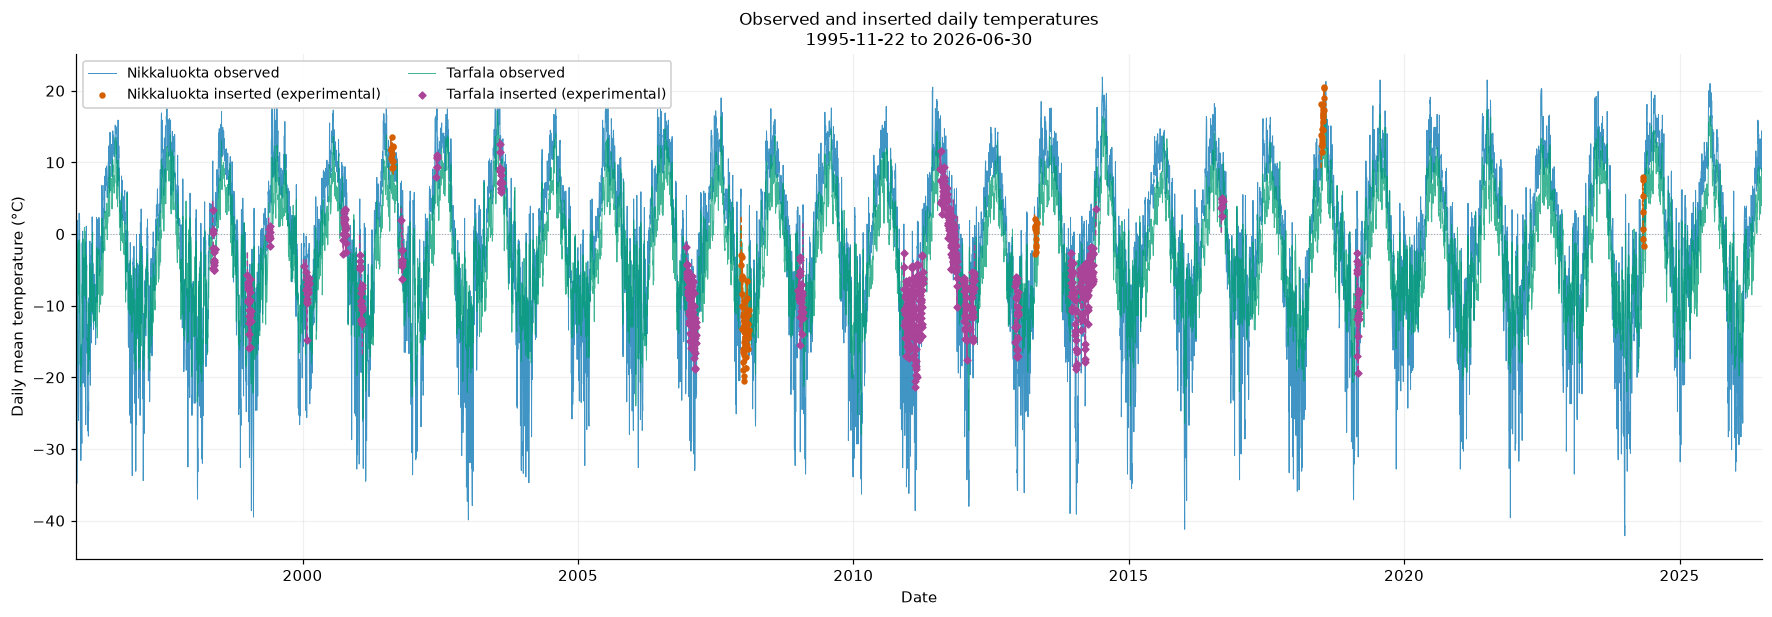

In [5]:
overview = cleaned.loc[OVERVIEW_START:OVERVIEW_END]
if overview.empty:
    raise ValueError("The selected overview dates contain no data.")

fig, ax = plt.subplots(figsize=(16, 5.5), layout="constrained")
for variable in TEMPERATURES:
    plot_station(ax, overview, variable)
format_axis(ax)
ax.set(
    title=(
        "Observed and inserted daily temperatures\n"
        f"{overview.index[0]:%Y-%m-%d} to {overview.index[-1]:%Y-%m-%d}"
    ),
    xlim=(overview.index[0] - pd.Timedelta(hours=12), overview.index[-1] + pd.Timedelta(hours=12)),
)
ax.legend(loc="upper left", ncols=2, fontsize=9, frameon=True, framealpha=0.95)
plt.show()

## Examples around inserted data

The gallery selects the **shortest**, **longest**, and **most recent** gap containing estimates for each station.
Duplicate choices are shown only once. All views include observed context before and after the selected gap where available.

The reference station has a different elevation and temperature regime, so the grey curve is not expected to match the reconstructed curve.

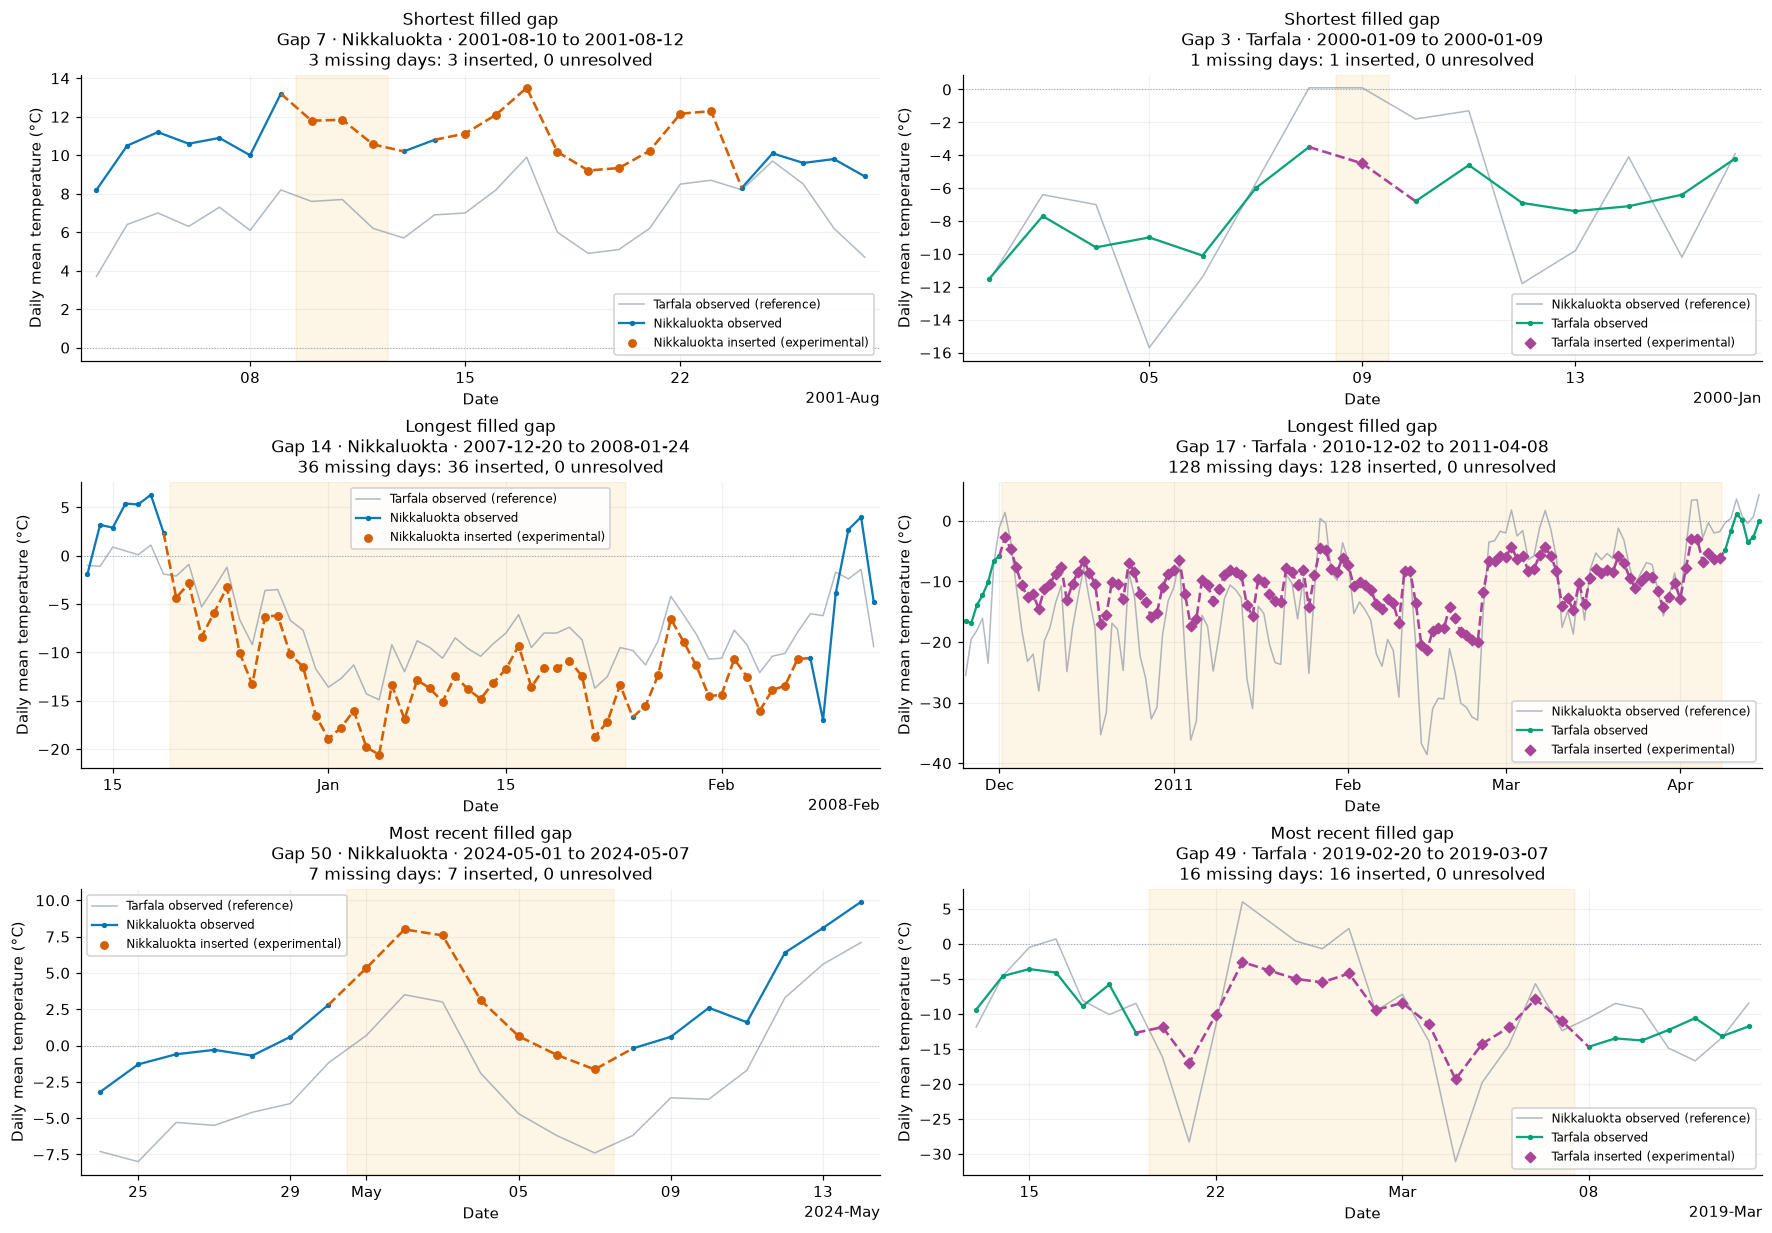

In [6]:
examples = []
seen = set()
for kind in ("Shortest", "Longest", "Most recent"):
    for variable in TEMPERATURES:
        choices = gaps.loc[gaps["variable"].eq(variable) & gaps.inserted_days.gt(0)]
        if choices.empty:
            continue
        if kind == "Shortest":
            selected = choices.sort_values(["days", "start"], kind="stable").index[0]
        elif kind == "Longest":
            selected = choices.sort_values(
                ["days", "start"], ascending=[False, True], kind="stable"
            ).index[0]
        else:
            selected = choices.sort_values("end", kind="stable").index[-1]
        if selected not in seen:
            examples.append((kind, selected))
            seen.add(selected)

if not examples:
    print("No inserted temperatures are present. The overview still shows observations.")
else:
    columns = min(2, len(examples))
    rows = math.ceil(len(examples) / columns)
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, 3.7 * rows),
        squeeze=False,
        layout="constrained",
    )
    for ax, (kind, gap_id) in zip(axes.flat, examples):
        plot_gap(gap_id, ax, context_observations=CONTEXT_OBSERVATIONS)
        ax.set_title(f"{kind} filled gap\n{ax.get_title()}")
    for ax in axes.flat[len(examples) :]:
        ax.set_visible(False)
    plt.show()

## Inspect a selected gap and its daily values

Change `CUSTOM_GAP_ID` in the settings cell and rerun this cell to inspect another interval.
With `None`, this selects the most recent gap containing estimates (or the most recent unresolved gap if no estimates exist).

The table highlights inserted days. A blank observed value paired with a candidate temperature is an estimate; the original observation remains missing.

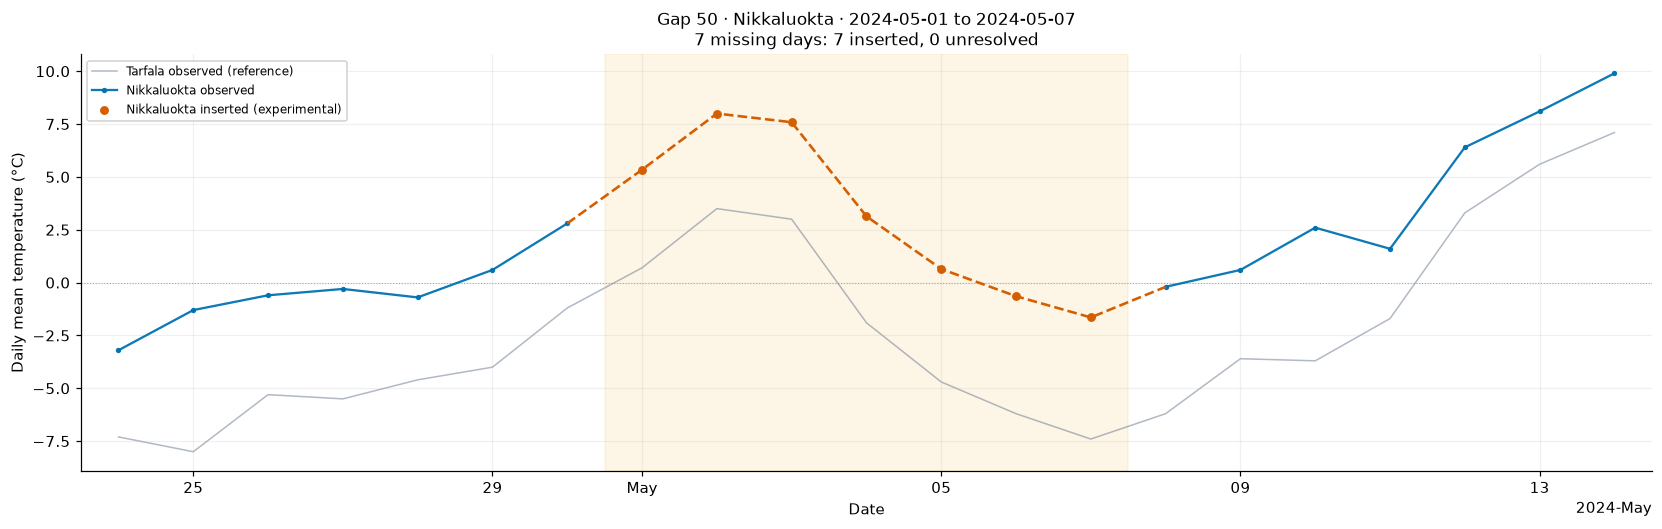

,Observed (°C),Candidate (°C),Inserted,Method,Tarfala observed (°C)
date,,,,,
2024-04-24,-3.20,-3.20,False,observed,-7.30
2024-04-25,-1.30,-1.30,False,observed,-8.00
2024-04-26,-0.60,-0.60,False,observed,-5.30
2024-04-27,-0.30,-0.30,False,observed,-5.50
2024-04-28,-0.70,-0.70,False,observed,-4.60
2024-04-29,0.60,0.60,False,observed,-4.00
2024-04-30,2.80,2.80,False,observed,-1.20
2024-05-01,—,5.34,True,cross_station_regression,0.70
2024-05-02,—,8.00,True,cross_station_regression,3.50


In [7]:
if gaps.empty:
    print("There are no original temperature gaps to inspect.")
else:
    if CUSTOM_GAP_ID is None:
        choices = gaps.loc[gaps.inserted_days.gt(0)]
        if choices.empty:
            choices = gaps
        selected_gap_id = choices.sort_values("end", kind="stable").index[-1]
    else:
        selected_gap_id = CUSTOM_GAP_ID

    frame = gap_context(selected_gap_id, CONTEXT_OBSERVATIONS)
    gap = gaps.loc[selected_gap_id]
    variable = gap["variable"]
    donor = next(name for name in TEMPERATURES if name != variable)
    fig, ax = plt.subplots(figsize=(15, 4.7), layout="constrained")
    plot_gap(selected_gap_id, ax, context_observations=CONTEXT_OBSERVATIONS)
    plt.show()

    values = pd.DataFrame(
        {
            "Observed (°C)": frame[f"{variable}_c"],
            "Candidate (°C)": frame[f"{variable}_candidate_c"],
            "Inserted": frame[f"{variable}_imputed"],
            "Method": frame[f"{variable}_imputation_method"],
            f"{STATIONS[donor]['label']} observed (°C)": frame[f"{donor}_c"],
        }
    )
    numeric_columns = values.select_dtypes(include="number").columns
    display(
        values.style.format({column: "{:.2f}" for column in numeric_columns}, na_rep="—")
        .format_index(lambda date: date.strftime("%Y-%m-%d"))
        .apply(
            lambda row: ["background-color: #FFF1D6" if row["Inserted"] else ""] * len(row),
            axis=1,
        )
    )

## How to read the plots

Check the join at each end, the daily variability during the gap, and whether estimates cross freezing thresholds.
A plausible join is a visual check, not a validation score: the missing observations are still unknown.
Use `data/cleaned/quality_report.md` for artificial-gap errors and SWE sensitivity.

This notebook only compares temperatures. It does not approve estimates for forecasting or alter the inputs used by existing snow calculations.